# Fördjupad modellutvärdering – prognosfel, Bias och höga PM2.5-värden

# Fördjupad modellutvärdering – prognosfel, Bias och höga PM2.5-värden

Denna analys kompletterar den tidigare modellutvärderingen med ett särskilt fokus på prognosfel vid höga PM2.5-koncentrationer och systematiska över- och underskattningar (Bias).

Syftet är att undersöka modellernas styrkor och begränsningar, jämföra deras resultat med persistence baseline och ta fram ett mer nyanserat underlag för val av champion-modell.





**Syfte:** Jämföra sju maskininlärningsmodeller med en enkel persistence baseline och identifiera lämpliga champion-kandidater utifrån valideringsdata.

Analysen följer fyra frågor:
1. Hur väl förutsäger modellerna PM2.5 generellt?
2. Hur fungerar de när PM2.5 är högt?
3. Slår de en enkel persistence-prognos?
4. Hur påverkar prioriteringar och variation mellan månader valet av champion?

**Avgränsning:** Modellerna väljs utifrån tränings- och valideringsdata. Testdata används först efter modellvalet för en oberoende slututvärdering.

## 1. Data och utvärderingsmetod

Vi använder samma förklarande variabler och tidsuppdelning för samtliga modeller. Prognoshorisonten är sex timmar. Huvudmåttet är **MAE** (genomsnittligt absolut fel, µg/m³). **RMSE** visar känslighet för stora fel, **R²** beskriver förklarad variation och **Bias** visar systematisk över-/underskattning (prognos minus faktiskt värde).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import load_config
from src.train_models import (
    load_train_val_data,
    build_model_registry,
    train_and_evaluate_models,
    persistence_baseline,
)

cfg = load_config(PROJECT_ROOT / "config.toml", PROJECT_ROOT)
X_train, y_train, X_val, y_val = load_train_val_data(
    train_path=cfg.train_processed,
    val_path=cfg.val_processed,
    features=cfg.features,
    target=cfg.target_column,
)

print("Träning:", X_train.shape, "| Validering:", X_val.shape)
print("Antal features:", X_train.shape[1])

Träning: (21555, 12) | Validering: (3562, 12)
Antal features: 12


### Definition av höga PM2.5-värden

Höga koncentrationer definieras här som värden **minst lika med 90:e percentilen i träningsmålet**. Gränsen beräknas inte från validerings- eller testdata, för att undvika dataläckage. Detta är en **projektintern analysgräns**, inte ett officiellt hälsogränsvärde.

In [2]:
high_pm25_threshold = y_train.quantile(0.90)
threshold_summary = pd.DataFrame({
    "Datamängd": ["Träning", "Validering"],
    "Observationer": [len(y_train), len(y_val)],
    "Höga värden": [(y_train >= high_pm25_threshold).sum(), (y_val >= high_pm25_threshold).sum()],
    "Andel höga (%)": [100 * (y_train >= high_pm25_threshold).mean(), 100 * (y_val >= high_pm25_threshold).mean()],
})
print(f"Tröskel: {high_pm25_threshold:.2f} µg/m³")
display(threshold_summary.round(2))

Tröskel: 14.42 µg/m³


,Datamängd,Observationer,Höga värden,Andel höga (%)
0,Träning,21555,2156,10.00
1,Validering,3562,616,17.29


## 2. Modellernas prestanda på valideringsdata

Vi tränar sju modeller på träningsdata och jämför dem på samma valideringsperiod. Först redovisas generell prognosprecision, därefter resultaten för observationer med höga PM2.5-värden.

In [3]:
models = build_model_registry(cfg.random_state)
results_df, trained_models = train_and_evaluate_models(
    models, X_train, y_train, X_val, y_val
)

High PM2.5 threshold: 14.42 µg/m³
Tränar Linear Regression...
Tränar Ridge Regression...
Tränar Random Forest...
Tränar HistGradientBoosting...
Tränar SVR...
Tränar LightGBM...
Tränar XGBoost...


In [4]:
general_cols = ["Modell", "Validation MAE", "Validation RMSE", "Validation R²", "Validation Bias"]
high_cols = ["Modell", "Validation High PM2.5 MAE", "Validation High PM2.5 Bias", "Validation High PM2.5 Count"]
print("Generell prestanda – lägst MAE först")
display(results_df[general_cols].sort_values("Validation MAE").reset_index(drop=True).round(3))
print(f"Höga PM2.5-värden (≥ {high_pm25_threshold:.2f} µg/m³) – lägst MAE först")
display(results_df[high_cols].sort_values("Validation High PM2.5 MAE").reset_index(drop=True).round(3))

Generell prestanda – lägst MAE först


,Modell,Validation MAE,Validation RMSE,Validation R²,Validation Bias
0,SVR,2.910,4.453,0.711,-0.816
1,HistGradientBoosting,2.971,4.557,0.697,-0.184
2,LightGBM,2.978,4.569,0.695,-0.118
3,Linear Regression,2.991,4.459,0.710,-0.155
4,Ridge Regression,2.991,4.459,0.710,-0.155
5,Random Forest,3.098,4.642,0.686,0.129
6,XGBoost,3.230,4.935,0.645,-0.071


Höga PM2.5-värden (≥ 14.42 µg/m³) – lägst MAE först


,Modell,Validation High PM2.5 MAE,Validation High PM2.5 Bias,Validation High PM2.5 Count
0,Linear Regression,6.399,-4.902,616
1,Ridge Regression,6.399,-4.902,616
2,Random Forest,6.421,-3.705,616
3,LightGBM,6.591,-3.809,616
4,HistGradientBoosting,6.611,-4.106,616
5,SVR,6.764,-5.784,616
6,XGBoost,7.027,-3.968,616


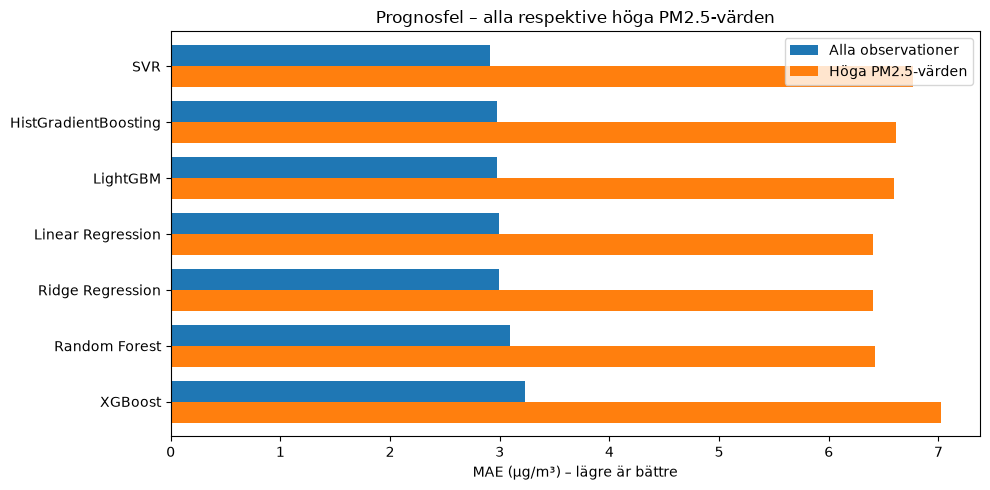

In [5]:
plot_df = results_df.set_index("Modell")[["Validation MAE", "Validation High PM2.5 MAE"]].sort_values("Validation MAE")
ax = plot_df.plot(kind="barh", figsize=(10, 5), width=0.75)
ax.invert_yaxis()
ax.set_xlabel("MAE (µg/m³) – lägre är bättre")
ax.set_ylabel("")
ax.set_title("Prognosfel – alla respektive höga PM2.5-värden")
ax.legend(["Alla observationer", "Höga PM2.5-värden"])
plt.tight_layout()
plt.show()

**Delresultat.** SVR har lägst generell MAE (cirka 2,91 µg/m³), medan Linear Regression och Ridge har lägst MAE bland ML-modellerna för höga koncentrationer (cirka 6,40 µg/m³). Samtliga modeller har negativ Bias vid höga koncentrationer. Random Forest har betydligt lägre träningsfel än valideringsfel, vilket tyder på överanpassning.

Resultaten säger ännu inte om ML-modellerna tillför något jämfört med en enkel prognos. Därför behövs en baseline.

## 3. Jämförelse med persistence baseline

**Persistence baseline** utgår från att det aktuella PM2.5-värdet består sex timmar framåt. En ML-modell bör jämföras med detta enkla alternativ, inte bara med andra ML-modeller.

In [ ]:
baseline_train_metrics, baseline_val_metrics = persistence_baseline(
    X_train, y_train, X_val, y_val
)
baseline_df = pd.DataFrame(
    [baseline_train_metrics, baseline_val_metrics],
    index=["Träning", "Validering"]
)
display(baseline_df.round(3))

### Förbättring i MAE jämfört med baseline

En positiv procentsats innebär lägre MAE än baseline; en negativ procentsats innebär högre MAE. Baseline visas som egen referensrad.

In [ ]:
comparison_pct = results_df[["Modell", "Validation MAE", "Validation High PM2.5 MAE"]].copy()
comparison_pct = pd.concat([
    comparison_pct,
    pd.DataFrame([{
        "Modell": "Persistence baseline",
        "Validation MAE": baseline_val_metrics["MAE"],
        "Validation High PM2.5 MAE": baseline_val_metrics["High PM2.5 MAE"],
    }])
], ignore_index=True)
comparison_pct["Förbättring totalt (%)"] = 100 * (
    baseline_val_metrics["MAE"] - comparison_pct["Validation MAE"]
) / baseline_val_metrics["MAE"]
comparison_pct["Förbättring höga (%)"] = 100 * (
    baseline_val_metrics["High PM2.5 MAE"] - comparison_pct["Validation High PM2.5 MAE"]
) / baseline_val_metrics["High PM2.5 MAE"]
display(comparison_pct.sort_values("Validation MAE").reset_index(drop=True).round(2))

**Delresultat.** SVR förbättrar generell MAE med cirka **6,4 %** jämfört med baseline. Vid höga koncentrationer är däremot **persistence baseline bättre än samtliga sju ML-modeller**. Detta är centralt för hur prognoserna kan användas och motiverar en närmare felanalys.

## 4. Felanalys – var gör modellerna fel?

Ett lågt totalt Bias behöver inte betyda att modellen saknar systematiska fel: överskattningar och underskattningar kan ta ut varandra. Vi granskar därför prognoserna mot de faktiska värdena och beräknar Bias separat för observationer under och över tröskeln.

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
max_value = max(float(y_val.max()), 60)
for ax, (namn, modell) in zip(axes.flat, trained_models.items()):
    y_pred = modell.predict(X_val)
    ax.scatter(y_val, y_pred, alpha=0.25, s=8)
    ax.plot([0, max_value], [0, max_value], "r--", linewidth=1)
    ax.set_title(namn)
    ax.grid(alpha=0.2)
axes.flat[-1].axis("off")
fig.supxlabel("Verkligt PM2.5 (µg/m³)")
fig.supylabel("Förutsagt PM2.5 (µg/m³)")
fig.suptitle("Verkliga och förutsagda värden – alla modeller")
plt.tight_layout()
plt.show()

In [ ]:
low_mask = y_val.to_numpy() < high_pm25_threshold
high_mask = ~low_mask
bias_rows = []
for namn, modell in trained_models.items():
    error = np.asarray(modell.predict(X_val)) - y_val.to_numpy()
    bias_rows.append({
        "Modell": namn,
        "Bias under tröskel": error[low_mask].mean(),
        "Bias höga värden": error[high_mask].mean(),
        "Bias totalt": error.mean(),
    })
bias_rows.append({
    "Modell": "Persistence baseline",
    "Bias under tröskel": (X_val["pm25"].to_numpy() - y_val.to_numpy())[low_mask].mean(),
    "Bias höga värden": baseline_val_metrics["High PM2.5 Bias"],
    "Bias totalt": baseline_val_metrics["Bias"],
})
display(pd.DataFrame(bias_rows).round(3))

**Tolkning.** Spridningsdiagrammen visar ett gemensamt mönster: prognoserna tenderar att ligga över den ideala linjen vid låga koncentrationer och under den vid höga koncentrationer. Tabellen ovan kvantifierar detta för båda grupperna. De negativa Bias-värdena vid höga koncentrationer visar att modellerna systematiskt underskattar just dessa observationer.

Detta begränsar vad prognoserna kan användas till, särskilt om målet är att uppmärksamma höga halter. En separat utvärdering av **varningsförmåga** skulle kräva andra mått, exempelvis recall för händelser över en relevant tröskel.

## 5. Champion-kandidater och viktat urval

Vi vill väga **generell MAE** mot **MAE vid höga koncentrationer**. Måtten normaliseras mot respektive baseline så att de får jämförbar skala:

\[
S = (1-w)\,
rac{MAE_{alla}}{MAE_{baseline,alla}} + w\,
rac{MAE_{höga}}{MAE_{baseline,höga}}
\]

Där \(w\) är vikten för höga värden. **Lägst poäng är bäst**, och baseline får poängen 1. Vikterna måste motiveras av prognosens tänkta användning, inte av vilken modell som råkar vinna. Eftersom höga observationer redan ingår i total MAE innebär viktningen att de avsiktligt ges extra betydelse.

RMSE och Bias används som kompletterande kontroller. R² viktas inte separat eftersom det i denna jämförelse till stor del överlappar med RMSE.

In [ ]:
vikt_hoga = 0.40  # ändra om projektets prioriteringar motiverar en annan vikt
ranking_df = comparison_pct[["Modell", "Validation MAE", "Validation High PM2.5 MAE"]].copy()
ranking_df["Viktad poäng"] = (
    (1 - vikt_hoga) * ranking_df["Validation MAE"] / baseline_val_metrics["MAE"]
    + vikt_hoga * ranking_df["Validation High PM2.5 MAE"] / baseline_val_metrics["High PM2.5 MAE"]
)
display(ranking_df.sort_values("Viktad poäng").reset_index(drop=True).round(3))

### Känslighetsanalys

En champion bör inte utses enbart utifrån en godtycklig vikt. Vi testar därför hur vinnaren ändras när prioriteringen av höga värden varierar.

In [ ]:
sensitivity_rows = []
for w in [0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]:
    score = (
        (1 - w) * ranking_df["Validation MAE"] / baseline_val_metrics["MAE"]
        + w * ranking_df["Validation High PM2.5 MAE"] / baseline_val_metrics["High PM2.5 MAE"]
    )
    best = score.min()
    winners = ranking_df.loc[np.isclose(score, best, atol=1e-5), "Modell"].tolist()
    sensitivity_rows.append({"Vikt höga (%)": int(w * 100), "Vinnare": " / ".join(winners), "Lägsta poäng": best})
display(pd.DataFrame(sensitivity_rows).round(3))

**Delresultat.** Vid låg vikt för höga värden väljs SVR, kring 40 % konkurrerar Linear Regression och Ridge, och vid högre vikt väljs persistence baseline. Det visar att champion-valet är **känsligt för verksamhetsprioriteringen**. Därför går vi vidare med SVR, Linear Regression och persistence baseline som kandidater och granskar stabilitet över tid.

## 6. Stabilitet över månader

En modell kan ha bra MAE totalt men prestera sämre under vissa perioder. Vi jämför därför kandidaterna månad för månad, både totalt och för höga PM2.5-värden. Först kontrolleras att tidsstämplarna från den bearbetade valideringsfilen ligger i samma radordning som modellernas målvariabel.

In [ ]:
val_raw = pd.read_csv(cfg.val_processed)
assert len(val_raw) == len(X_val) == len(y_val), "Antalet rader matchar inte"
assert np.allclose(val_raw[cfg.target_column].to_numpy(), y_val.to_numpy(), equal_nan=True), "Target/radordning matchar inte"

monthly_df = pd.DataFrame({
    "tid": pd.to_datetime(val_raw["tid"], utc=True),
    "Verkligt": y_val.to_numpy(),
    "SVR": trained_models["SVR"].predict(X_val),
    "Linear Regression": trained_models["Linear Regression"].predict(X_val),
    "Persistence baseline": X_val["pm25"].to_numpy(),
})
# Kontrollera att vår manuella persistence-prognos motsvarar projektets baseline-funktion.
manual_baseline_mae = (monthly_df["Verkligt"] - monthly_df["Persistence baseline"]).abs().mean()
assert np.isclose(manual_baseline_mae, baseline_val_metrics["MAE"]), "Persistence-definitionen skiljer sig från baseline-funktionen"

monthly_df["Månad"] = monthly_df["tid"].dt.tz_convert("Europe/Stockholm").dt.strftime("%Y-%m")
for namn in ["SVR", "Linear Regression", "Persistence baseline"]:
    monthly_df[f"{namn} MAE"] = (monthly_df["Verkligt"] - monthly_df[namn]).abs()
mae_cols = ["SVR MAE", "Linear Regression MAE", "Persistence baseline MAE"]
monthly_mae = monthly_df.groupby("Månad")[mae_cols].mean()
print("MAE per månad – samtliga observationer")
display(monthly_mae.round(3))

In [ ]:
monthly_high = monthly_df[monthly_df["Verkligt"] >= high_pm25_threshold]
monthly_high_mae = monthly_high.groupby("Månad")[mae_cols].mean()
monthly_high_mae["Antal höga värden"] = monthly_high.groupby("Månad").size()
print("MAE per månad – höga PM2.5-värden")
display(monthly_high_mae.round(3))

monthly_summary = monthly_df.groupby("Månad").agg(
    Antal_observationer=("Verkligt", "size"),
    Antal_höga=("Verkligt", lambda x: (x >= high_pm25_threshold).sum()),
    Medel_PM25=("Verkligt", "mean"),
)
monthly_summary["Andel höga (%)"] = 100 * monthly_summary["Antal_höga"] / monthly_summary["Antal_observationer"]
print("Förekomst av höga PM2.5-värden per månad")
display(monthly_summary.round(2))

**Tolkning.** I den tidigare månadsjämförelsen hade SVR lägst generell MAE under februari, april och maj, medan Linear Regression låg marginellt bättre till i januari och mars. Vid höga koncentrationer var persistence baseline ofta stark, men inte bäst varje månad. Antalet höga observationer varierade kraftigt mellan månaderna, vilket gör att enskilda månadsresultat behöver tolkas försiktigt.

Mönstret med fler höga observationer i januari–mars än i april–maj är förenligt med säsongsvariation, men fem månader under ett år räcker inte för att fastställa ett generellt årstidsmönster.

## 7. Samlad bedömning och nästa steg

- **SVR:** starkast generell MAE, men tydlig underskattning vid höga koncentrationer.
- **Linear Regression / Ridge:** bra kompromiss vid exempelvis 60/40-viktning; skillnaden mot baseline är liten.
- **Persistence baseline:** stark referens, särskilt vid höga koncentrationer; kan vara ett rimligt slutligt val beroende på användningsområdet.

**Ingen entydig champion kan utses utan en motiverad prioritering.** Välj i första hand urvalskriterier utifrån användningsområdet, granska sedan RMSE, Bias och stabilitet för de främsta kandidaterna. Om syftet är att varna för höga halter bör även klassificeringsmått för sådana händelser utvärderas.

**Nästa steg:** Dokumentera det beslutade urvalskriteriet och välj champion på valideringsdata. Utvärdera därefter den låsta modellen en gång på den separata testperioden. Testresultatet ska inte användas för att justera viktningen i efterhand.